# `rioxarray`

In this lesson we will introduce [`rioxarray`](https://corteva.github.io/rioxarray/stable/), a Python extension for `xarray` to manipulate `xarray.DataArray`s as rasters. 

The name `rioxarray` stands for *raster input/output + xarray*. 

## About the data
The raster files we will use today come from the [US National Agriculture Imagery Program (NAIP)](https://naip-usdaonline.hub.arcgis.com). 
NAIP images are are high-resolution aerial images with four spectral bands: red (R), green (G), blue (B) and near-infrared (NIR). 
The raster's we'll use today are from 2020.

The data used in this lesson was pre-processing from a complete NAIP scene to separate the RGB bands from the NIR band and reduce the spatial extent. 
The data was accessed through [Microsoft's Planetary Computer NAIP data repository](https://planetarycomputer.microsoft.com/dataset/naip#overview).

## Import a TIF file

Let's start by loading the libraries we will use: 

In [24]:
# Import packages
import os              
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

import xarray as xr
import rioxarray as rioxr

There are [multiple ways of opening a TIF file using `xarray` or `rioxarray`](https://corteva.github.io/rioxarray/html/getting_started/getting_started.html). 
Using the `rioxarray.open_rasterio()` function to open the TIF file is a simple way to import the raster file as an `xarray.DataArray` and make sure all our geospatial data gets loaded correctly:

In [4]:
# Import NIR TIF file
fp = os.path.join('data','NAIP_SB','NAIP_SB_nir.tif')
nir = rioxr.open_rasterio(fp)
nir

<xarray.DataArray (band: 1, y: 3208, x: 2419)> Size: 8MB
[7760152 values with dtype=uint8]
Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [5]:
print('Shape: ', nir.shape)
print('Data type: ', nir.dtype, '\n')

Shape:  (1, 3208, 2419)
Data type:  uint8 



In [ ]:
# Retrieve array of data
print(type(nir.values))
nir.values

<class 'numpy.ndarray'>


array([[[167, 164, 161, ..., 147, 152, 151],
        [170, 170, 168, ..., 151, 149, 154],
        [176, 177, 177, ..., 151, 151, 151],
        ...,
        [ 94,  88, 101, ...,  83,  88,  79],
        [108,  95, 103, ...,  92,  91,  75],
        [ 94,  90, 104, ...,  87,  88,  82]]], dtype=uint8)

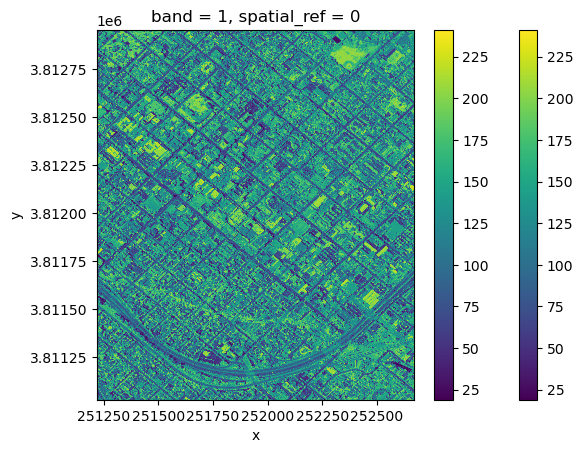

In [8]:
nir.plot()

## Drop a dimension

In [9]:
print("Sizes of dimensions:", dict(nir.sizes))

Sizes of dimensions: {'band': 1, 'y': 3208, 'x': 2419}


This is making this xarray.DataArray three-dimensional when it is not needed. We can “squeeze this dimension” of length 1 using the squeeze() method. We pass it the name of the dimension we want to remove, in this case ‘band’, and drop=True to also get rid of the coordinate associated with this dimension.

- `band` has length 1, so it makes the `xarray` 3-D for no reason
- `squeeze` removes a dimension of length 1
- `drop=True` remove the coords for that dimension

In [10]:
# Original dimensions and coordinates
print(nir.dims, nir.coords,'\n')

# Remove length 1 dimension (band) and its coordinate
nir = nir.squeeze('band', drop=True)
print(nir.dims, nir.coords)

('band', 'y', 'x') Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0 

('y', 'x') Coordinates:
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0


## `rio` accessor

Remember an accessor in Python lets us access a different set of properties of an object. We have previously used accessors like .str and .dt in pandas to work with strings and dates. In this lesson, we will use the .rio accessor for an xarray.DataArray to access its raster properties. For example, we can access the number of bands, height, width, spatial bounding box, and CRS:

In [11]:
# Examine raster attributes using rio accessor
print('Number of bands: ', nir.rio.count)
print('Height: ', nir.rio.height)
print('Width: ', nir.rio.width, '\n')

print('Spatial bounding box: ')
print(nir.rio.bounds(), '\n')

print('CRS: ', nir.rio.crs)

Number of bands:  1
Height:  3208
Width:  2419 

Spatial bounding box: 
(251218.8, 3811027.2, 252670.19999999998, 3812952.0) 

CRS:  EPSG:26911


## Multi-band raster

In [15]:
# Import RGB raster
fp = os.path.join('data','NAIP_SB','NAIP_SB_rgb.tif')
rgb = rioxr.open_rasterio(fp)
rgb

<xarray.DataArray (band: 3, y: 3208, x: 2419)> Size: 23MB
[23280456 values with dtype=uint8]
Coordinates:
  * band         (band) int64 24B 1 2 3
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

Notice this raster has three bands, instead of one. This makes sense because we know these bands correspond to the red, green and blue bands of the image.

### Check-In

Obtain the following information about the RGB raster: shape, number of bands, data type of its values and CRS.

In [16]:
# Original dimensions and coordinates
print(rgb.dims, rgb.coords,'\n')

# Examine raster attributes using rio accessor
print('Number of bands: ', rgb.rio.count)
print('Height: ', rgb.rio.height)
print('Width: ', rgb.rio.width, '\n')

print('Spatial bounding box: ')
print(rgb.rio.bounds(), '\n')

print('CRS: ', rgb.rio.crs)

('band', 'y', 'x') Coordinates:
  * band         (band) int64 24B 1 2 3
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0 

Number of bands:  3
Height:  3208
Width:  2419 

Spatial bounding box: 
(251218.8, 3811027.2, 252670.19999999998, 3812952.0) 

CRS:  EPSG:26911


Finally, let’s plot this raster. Since it has three bands, we can plot it as an image using the .plot.imshow() method, which will interpret the three bands of the object as RGB.

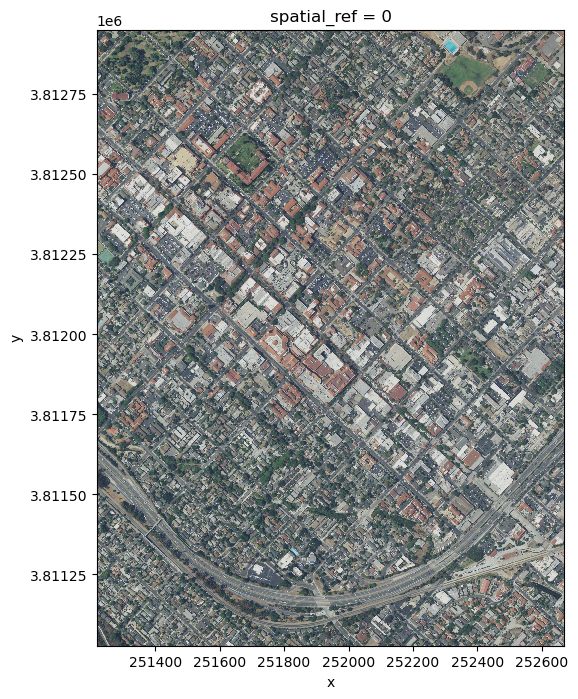

In [17]:
# Plot three bands as RGB image
rgb_aspect_ratio = rgb.rio.width / rgb.rio.height  # Raster's aspect ratio
rgb.plot.imshow(figsize=(8*rgb_aspect_ratio,8))  # (width, height) in inches

## Clip a raster

Our area of interest (AOI) for this lesson is a smaller region that includes only a few blocks around the NCEAS building. This is outlined in a GeoJSON file:

<Axes: >

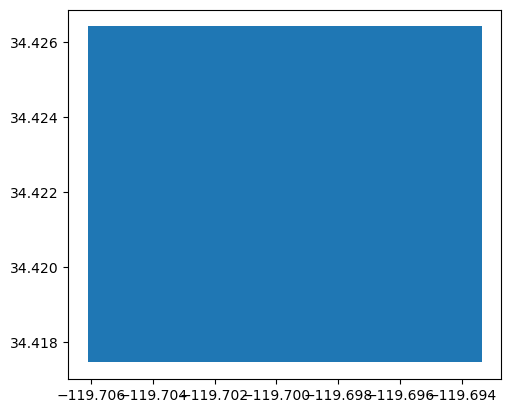

In [20]:
fp = os.path.join('data', 'SB_aoi.geojson')
aoi = gpd.read_file(fp)
aoi.plot()

Remember: if two geospatial datasets will interact they need to be in the same CRS. In our case, the AOI geopandas.GeoDataFrame does not have the same CRS as the rasters:

In [21]:
# Examine CRSs
print('aoi CRS: ', aoi.crs)
print('nir CRS: ', nir.rio.crs)
print('rgb CRS: ', rgb.rio.crs)

aoi CRS:  EPSG:4326
nir CRS:  EPSG:26911
rgb CRS:  EPSG:26911


In [22]:
# Reproject AOI to RGB CRS
aoi = aoi.to_crs(rgb.rio.crs)
assert aoi.crs == rgb.rio.crs

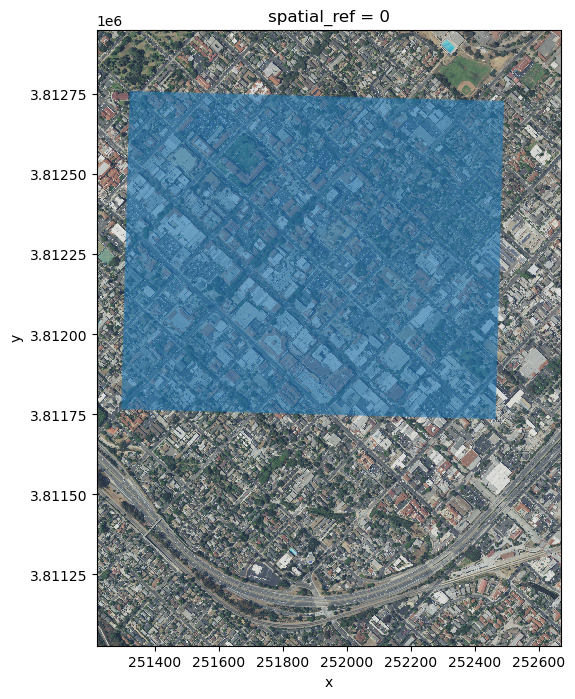

In [25]:
# Plot of RGB raster with AOI overlay
fig, ax = plt.subplots(figsize=(8 * rgb_aspect_ratio, 8))
rgb.plot.imshow(ax=ax)
aoi.plot(ax=ax, alpha=0.6)
plt.show()

To clip the raster to the AOI’s bounding box we use the .rio.clip_box() method:

In [26]:
# Clip rasters to AOI
rgb_small = rgb.rio.clip_box(*aoi.total_bounds)
nir_small = nir.rio.clip_box(*aoi.total_bounds)

Notice a few things:

- we had to use the .rio accessor to access the clip_box() method
- .rio.clip_box() usual parameters are minx, miny, maxx, maxy, the same four values the total_bounds attribute gave us when we clipped with a bounding box using gpd.clip(). We are using the * asterisk as an unpacking operator to get these from the array aoi.total_bounds.
- .rio.clip_box() keeps everything inside the AOI’s bounding box, not only the AOI itself. To clip a raster to the exact outline of the AOI we can use .rio.clip() with the AOI’s geometry: nir.rio.clip(aoi.geometry).

Original shape:  (3208, 2419)
Clipped shape:  (1710, 1995)


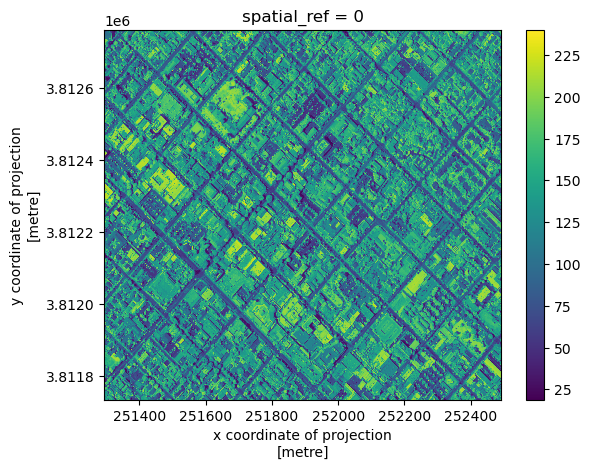

In [27]:
# Examine clipped data 
print('Original shape: ', nir.shape)
print('Clipped shape: ', nir_small.shape)

nir_small.plot()

### Check-In

Examine the same updates for the RGB data.

Original shape:  (3, 3208, 2419)
Clipped shape:  (3, 1710, 1995)


(array([ 199114.,  848007., 1788064., 2171943., 1614713., 1121663.,
        1059364.,  784346.,  551000.,   96136.]),
 array([ 32. ,  52.7,  73.4,  94.1, 114.8, 135.5, 156.2, 176.9, 197.6,
        218.3, 239. ]),
 <BarContainer object of 10 artists>)

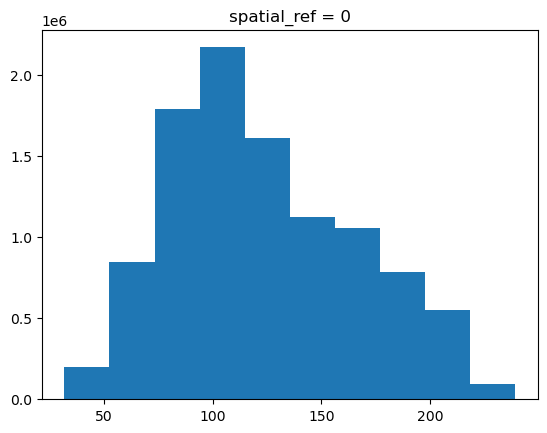

In [28]:
# Examine clipped data 
print('Original shape: ', rgb.shape)
print('Clipped shape: ', rgb_small.shape)

rgb_small.plot()

## Raster math

We often want to perform calculations on rasters to create a new output raster, commonly known as “raster math”.

In our case, we are interested in computing the Normalized Difference Vegetation Index (NDVI) over our AOI. The NDVI is an index commonly used to check if an area has live green vegetation or not.

According to NASA’s Earth Observatory [2], NDVI values always range from -1 to 1, and areas with no green leaves give values close to zero. Typical values for different surfaces are:
            
            Very low values of NDVI (0.1 and below) correspond to barren areas of rock, sand, or snow. Moderate values represent shrub and grassland (0.2 to 0.3), while high values indicate temperate and tropical rainforests (0.6 to 0.8).

Water and many artificial surfaces, like roofs and pavement, often have NDVI values close to zero or negative.

The NDVI is calculated using the NIR and red bands. The formula is:

            NDVI = (NIR - Red)/(NIR + Red)

First, let’s select the red band:

In [29]:
# Select dimension by name and coordinate by label
red_small = rgb_small.sel(band=1)
red_small

<xarray.DataArray (y: 1710, x: 1995)> Size: 3MB
[3411450 values with dtype=uint8]
Coordinates:
    band         int64 8B 1
  * x            (x) float64 16kB 2.513e+05 2.513e+05 ... 2.525e+05 2.525e+05
  * y            (y) float64 14kB 3.813e+06 3.813e+06 ... 3.812e+06 3.812e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

We can perform raster calculations using the same arithmetic we use for numpy.ndarrays (because, underneath it all, that’s what they are).

### Check-In

Before we calculate the NDVI, make a prediction. Our area of interest is downtown Santa Barbara. About what share of the area do you expect to have positive NDVI values? What values do you expect for roofs and streets?
- Higher roofs + streets, fewer NDVI. But it's SB, so more NDVI than a denser city.

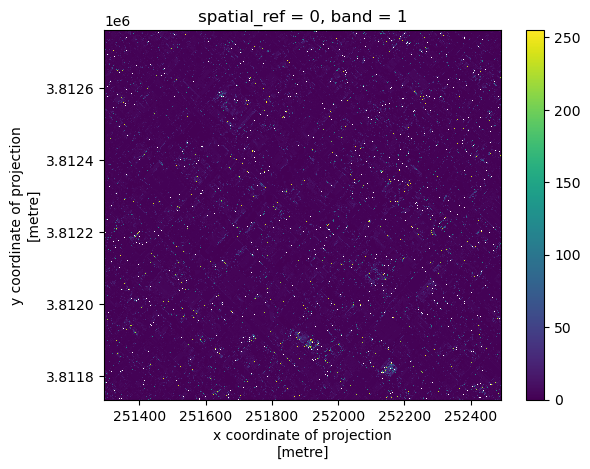

In [30]:
# NDVI calculation
ndvi = (nir_small - red_small)/(nir_small + red_small)
ndvi.plot()

Do these results look as expected? Remember that NDVI values must be between -1 and 1. Let’s check the range of our results:

In [31]:
print('Minimum NDVI:', ndvi.min().values)
print('Maximum NDVI:', ndvi.max().values)

Minimum NDVI: 0.0
Maximum NDVI: inf


None of the values are negative and some are infinite, so **something went wrong**.

### Data Type Issues

The uint8 (8-bit unsigned integer) is a very small data type that only holds integers from 0 up to 255. In particular, calculations don’t return what we are used to when working with integers (they’re done modulo 256):

In [32]:
np.uint8(150) + np.uint8(150)

/var/folders/27/3jvf7rts3gjbq79rmz16ywp40000gq/T/ipykernel_58841/1890984988.py:1: RuntimeWarning: overflow encountered in scalar add
  np.uint8(150) + np.uint8(150)


44

In the NDVI formula we have to subtract and add the NIR and red values, and both operations can go outside the uint8 range:

- when NIR + Red is greater than 255, the sum wraps around to a small number;
- when Red is greater than NIR, NIR - Red should be negative, but uint8 cannot hold negative numbers, so the result wraps around to a large positive number.

### Updating data types

To be able to perform the calculation successfully, we will need to update the data type of our rasters to int16, which will be big enough to hold all the numbers that appear in the calculations:

RED: original dtype: uint8 .... converted dtype: int16
NIR: original dtype: uint8 .... converted dtype: int16


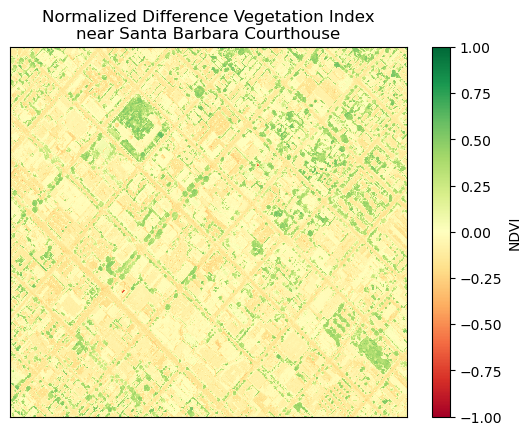

In [33]:
# Update data type to int16 to perform NDVI calculation
red16 = red_small.astype('int16')
nir16 = nir_small.astype('int16')

print('RED: original dtype:', rgb_small.dtype, '.... converted dtype:', red16.dtype)
print('NIR: original dtype:', nir.dtype, '.... converted dtype:', nir16.dtype)

# Calculate NDVI
ndvi = (nir16 - red16)/(nir16+red16)

# Plot
fig, ax = plt.subplots()  # Create figure and axes
ndvi.plot(
    ax=ax,
    cmap="RdYlGn",  # Colormap for NDVI
    vmin=-1,  # Minimum value
    vmax=1,   # Maximum value
    cbar_kwargs={"label": "NDVI"}  # Label for color bar
)
ax.set_title("Normalized Difference Vegetation Index\nnear Santa Barbara Courthouse")  # Add title

# Remove axes ticks
ax.set_xticks([])  
ax.set_yticks([])  

# Remove axes labels
ax.set_xlabel("")  
ax.set_ylabel("")  

plt.show()

### Check-In

A city planner wants to use this NDVI map to find blocks that need more street trees. Write two or three sentences on what this map can and can’t tell them.

- This map can tell them where land types that reflect high amounts of NIR are located - some of those are trees, some are grass or other types of vegetation, and there's a chance some green areas might be non-vegetation with high NIR reflectance. Generally though, we can expect more vegetation in the green areas of the above map.

Converting the rasters to int16 fixed the calculation, but the final map still has limits:…it shows a single summer day in 2018, and its values are 8-bit brightness values from a camera, not physical measurements of reflected light. A result that looks right is not the same as a result that is right, so always check your outputs against what you know about the data!